# Lab 04 · One configured NDVI job

Automated Workflows in Satellite Image Processing · Version 1.0 · 26 October 2026

In Lab 3 you acquired small red and NIR subsets and kept enough records to explain
where they came from. Today you turn those files into one repeatable processing
job. A later workflow manager will call this same job for many scenes.

The calculation is short. Most of the work is deciding what the calculation means,
checking its inputs, and keeping an honest account when execution fails.

You will write the database extension, repair three small functions, then run the
supplied CLI through success, reuse and recovery. Keep this notebook beside its
companion files. Start with README.md if you need to add packages.


In [1]:
from pathlib import Path
from contextlib import closing
import json
import sqlite3
import sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import yaml
import lab04_cli as commands
import check_lab04 as checks
import ndvi_job as job
import processing_store as store

ROOT = Path.cwd()
assert (ROOT / "lab04_cli.py").is_file(), "Open this notebook from the Lab04 folder."

def cli(*arguments, expected=(0,)):
    args = commands.parser().parse_args(list(map(str, arguments)))
    cfg = job.load_config(args.config)
    if args.command == "plan":
        with closing(store.connect(cfg["database"])) as connection:
            inputs = {role: store.input_record(connection, artifact)
                      for role, artifact in cfg["science"]["inputs"].items()}
        spec, fingerprint = job.repairs.make_request_spec(
            cfg["science"], inputs, job.environment(), cfg["runtime"])
        return {"request_id": "request-" + fingerprint, "normalized_spec": spec}
    if args.command == "run":
        result = job.run(cfg, force=args.force, simulate=args.simulate)
        assert result["status"] in ("succeeded", "reused"), result
        return result
    if args.command == "restore-input":
        return commands.restore_input(cfg)
    if args.command == "reconcile":
        return job.reconcile(cfg, args.attempt_id, args.confirm_stopped)
    if args.command == "report":
        result = commands.report(cfg)
        if args.out:
            destination = Path(args.out)
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_text(json.dumps(result, indent=2), encoding="utf-8")
        return result
    raise ValueError(args.command)

def check(part):
    passed = True
    for name in (checks.CHECKS if part == "all" else [part]):
        try:
            checks.CHECKS[name]()
            print("PASS", name)
        except Exception as exc:
            passed = False
            print("FAIL", name, str(exc))
    return passed

def query(config, sql, params=()):
    config = Path(config).resolve()
    settings = yaml.safe_load(config.read_text())
    database = (config.parent / settings["database"]).resolve()
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as connection:
        connection.row_factory = sqlite3.Row
        connection.execute("PRAGMA foreign_keys=ON")
        return [dict(row) for row in connection.execute(sql, params)]

print("Python:", sys.version.split()[0], "Rasterio:", rasterio.__version__)

Python: 3.13.7 Rasterio: 1.5.2


## Exercise 1 · Write the processing schema

Write all six tables in student_processing_schema.sql using SCHEMA_CONTRACT.md.
You already designed the acquisition tables in Lab 3; support/ contains those
completed tables only. You are designing the processing extension here.

Start by explaining the difference between these records:

- A request to compute NDVI from two exact artifacts under specified settings.
- An attempt that could succeed, fail, stop unexpectedly or reuse a result.
- A file artifact whose bytes and interpretation are identified.
- A current location where those bytes might or might not still exist.

Lab 3 requires every artifacts row to reference an acquisition subset. NDVI is a
derived product. The processing registry links acquired inputs back to that table
and stores derived products without inventing acquisition records.

Decide which keys allow two retries of one request, while preventing two red
inputs in the same role. Decide which failures a foreign key can detect, and which
require checking files. Keep the existing discovery runs unchanged.

Run the check whenever you want feedback. Its failures are expected until your
schema is complete.

In [2]:
schema_ok = check("schema")

PASS schema


Explain one constraint that prevents bad lineage, and one condition that your
schema cannot establish by itself.

*Write here.*

The composite foreign key links a reused attempt to an attempt of the same request, and schema cannot verify that a file exists or contains valid bytes.

## Exercise 2 · What makes this the same request?

Repair make_request_spec in repair_functions.py. It currently uses dictionary
iteration order, omits important evidence and includes a storage path.

Return (normalized_spec, fingerprint). The normalized spec must be JSON compatible
and contain the stage, normalized scientific settings, ordered red/NIR input
records, environment and the policy name exact_environment_v1.

Keep all scientific settings, including a calibration review when present. Use
each input's artifact_id, sha256, size_bytes, raster and lineage; keep role names
explicit and in red, then nir order. Exclude registration times and runtime paths.
Normalize numeric parameters so 1 and 1.0 have the same interpretation. Produce
SHA-256 from JSON with sorted keys, compact separators and no NaN values.

This lab uses a conservative equivalence policy: a code or environment change
creates a new request. A later policy could permit equivalence across tested
environments, but that requires an explicit decision.

Predict the result of each change before running the check:

| Change | Same request or different request? Why? |
| --- | --- |
| Write to a different disk | |
| Reorder YAML keys | |
| Retry after a missing file is restored | |
| Change the AOI or input checksum | |
| Change the denominator threshold | |
| Repair the algorithm implementation | |
| Change the calibration interpretation | |

In [3]:
identity_ok = check("identity")

PASS identity


## Exercise 3 · A program can finish and still be wrong

Repair validate_pair and calculate_ndvi in repair_functions.py. These are logical
repairs: the supplied functions execute, but their assumptions are incomplete.

validate_pair must reject different scenes, collections, AOIs or extraction
recipes; incorrect band roles; and incompatible CRS, shape or pixel transforms.
Check that required radiometric metadata are finite and the scale is positive.
Equal shapes do not establish matching ground positions. This stage requires a
matching grid; resampling would need its own explicit preparation policy.

calculate_ndvi receives the stored DN arrays and the effective calibration chosen
in the request. Mask original nodata, convert before subtraction or addition, then
apply scale and offset separately for each band. Use
NDVI = (NIR reflectance - red reflectance) / (NIR reflectance + red reflectance).
Return float32, put NaN at invalid pixels and at denominators with absolute value
at most epsilon, and leave the inputs unchanged. Do not clip the saved values.

The calculation must support nonzero offsets. The demo's reviewed offset 0 is not
a reason to hard-code zero. The checks use the real arrays with their original
metadata as well as a deliberately high denominator threshold.

In [4]:
pair_ok = check("pair")
ndvi_ok = check("ndvi")

PASS pair
PASS ndvi


Explain these two bugs with a concrete example from the metadata or arrays:

1. Why can uint16 subtraction give the wrong sign?
2. Why does a shared multiplicative factor cancel in NDVI, while a shared additive
   offset generally does not?

*Write here.*

1. At pixel (10, 196), uint16 subtraction gives `2580 − 2876 = 65240` instead of `−296`.
2. A shared scale cancels in the ratio, while an offset of `−0.1` subtracts `0.2` from the denominator.

## Run one complete job

Finish the repairs before proceeding. Restart the kernel after changing Python files,
so the following cells use the saved implementations.

Use your own completed Lab 3 catalogue through the init/inputs/configure commands
in README.md, then change CONFIG below. Or leave the default to import the small
preserved real example. This explicit local route works without network access.
All following main-run cells use the CONFIG you choose.

In [5]:
assert check("all"), "Finish the schema and function repairs first."

CONFIG = Path("config/ndvi.yml")
assert CONFIG.is_file(), "Create the configuration using the README commands first."
print(CONFIG.read_text())

PASS schema
PASS identity
PASS pair
PASS ndvi
database: C:\Users\micha\AGH\Automated workflows in satellite image processing\automated-workflows-labs\Labs\Lab04\state\catalogue.sqlite
science:
  stage: ndvi_v1
  grid_policy: require_match
  scaling: reviewed_calibration
  mask_policy: nodata_only
  denominator_epsilon: 1.0e-06
  min_valid_fraction: 0.1
  calibration:
    red:
      sha256: 8363a5d2259d08d542985156aae667a6d37211dad1900f8c836c93f055c60a2a
      scale: 0.0001
      offset: 0.0
      evidence: Local pixels, grid and radiometric metadata match the preserved Lab04
        sample. Interpretation follows NDVI_Visual_Investigation_v1_20261022_Student/CALIBRATION_REVIEW.md;
        captured boa_offset_applied=true conflicts with offset=-0.1. Teaching review
        for these exact local hashes; no independent source JP2 comparison.
    nir:
      sha256: b8cf04708203ae6ee6a7306f4232b7a69370a397a14a05da1dd41bdb45bf0e49
      scale: 0.0001
      offset: 0.0
      evidence: Local p

Inspect the configuration before running. Which artifact fills each role? Where
will the output persist? What calibration does it request? What does nodata_only
say about clouds?

The plan command resolves identity and prints the normalized request without
registering a request or creating an attempt.

In [6]:
plan = cli("plan", "--config", CONFIG)
print("Planned request:", plan["request_id"])
print(json.dumps(plan["normalized_spec"]["settings"], indent=2))
first = cli("run", "--config", CONFIG)
print(json.dumps(first, indent=2))
assert first["request_id"] == plan["request_id"]

Planned request: request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b
{
  "stage": "ndvi_v1",
  "grid_policy": "require_match",
  "scaling": "reviewed_calibration",
  "mask_policy": "nodata_only",
  "denominator_epsilon": 1e-06,
  "min_valid_fraction": 0.1,
  "calibration": {
    "red": {
      "sha256": "8363a5d2259d08d542985156aae667a6d37211dad1900f8c836c93f055c60a2a",
      "scale": 0.0001,
      "offset": 0,
      "evidence": "Local pixels, grid and radiometric metadata match the preserved Lab04 sample. Interpretation follows NDVI_Visual_Investigation_v1_20261022_Student/CALIBRATION_REVIEW.md; captured boa_offset_applied=true conflicts with offset=-0.1. Teaching review for these exact local hashes; no independent source JP2 comparison."
    },
    "nir": {
      "sha256": "b8cf04708203ae6ee6a7306f4232b7a69370a397a14a05da1dd41bdb45bf0e49",
      "scale": 0.0001,
      "offset": 0,
      "evidence": "Local pixels, grid and radiometric metadata match the preserved 

Predict what the next invocation changes in the database. Then run it. If you
have already run the notebook, the first result above may itself be a reuse.

In [7]:
repeat = cli("run", "--config", CONFIG)
print(json.dumps(repeat, indent=2))
assert repeat["request_id"] == first["request_id"]
assert repeat["attempt_id"] != first["attempt_id"]
assert repeat["status"] == "reused"

{
  "status": "reused",
  "request_id": "request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b",
  "attempt_id": "attempt-175582a8505849b89d4229ec5148b02c",
  "artifact_id": "output-1d3743d6d4a14da581627e99c69af7c9f40f8a2bb63aae6bf160668c473ebcf7",
  "path": "C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab04\\outputs\\attempt-8b3a746be88d456e97b1a9cf75cf05f6.ndvi.tif"
}


### Inspect the raster and its record

The display below uses a fixed NDVI color range. That only changes the display;
it does not clip the stored raster. Look at the reported coverage and range too.
No cloud classification data have been used.

Provenance tags: {'ATTEMPT_ID': 'attempt-8b3a746be88d456e97b1a9cf75cf05f6', 'CLOUD_SCREENED': 'false', 'MASK_POLICY': 'nodata_only', 'REQUEST_ID': 'request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b', 'STAGE': 'ndvi_v1', 'AREA_OR_POINT': 'Area'}


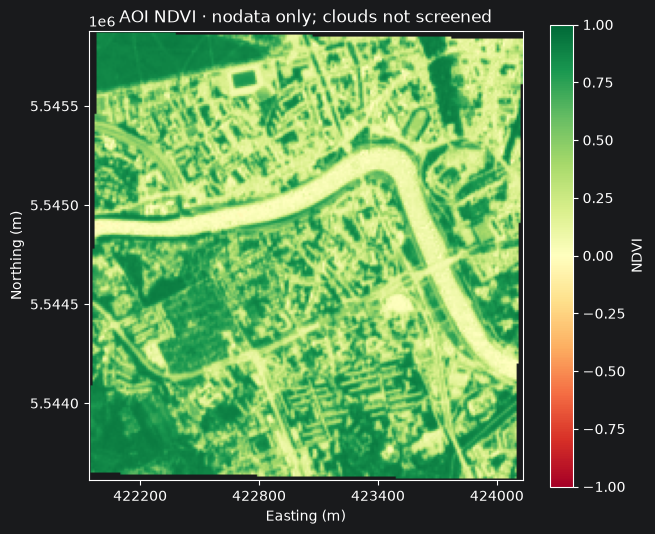

In [8]:
output_path = Path(repeat["path"])
from matplotlib.ticker import MaxNLocator
with rasterio.open(output_path) as source:
    ndvi = source.read(1, masked=True)
    bounds = source.bounds
    print("Provenance tags:", source.tags())
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1,
                      extent=(bounds.left, bounds.right, bounds.bottom, bounds.top))
    ax.set(title="AOI NDVI · nodata only; clouds not screened", xlabel="Easting (m)", ylabel="Northing (m)")
    ax.xaxis.set_major_locator(MaxNLocator(4))
    fig.colorbar(image, ax=ax, label="NDVI")
    plt.show()

In [9]:
history = query(CONFIG, """SELECT attempt_id,request_id,status,stage,started_at,finished_at,
    error_code,reused_from_attempt_id FROM processing_attempts ORDER BY started_at""")
history

[{'attempt_id': 'attempt-8b3a746be88d456e97b1a9cf75cf05f6',
  'request_id': 'request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b',
  'status': 'succeeded',
  'stage': 'complete',
  'started_at': '2026-11-02T23:28:51.890705Z',
  'finished_at': '2026-11-02T23:28:51.952318Z',
  'error_code': None,
  'reused_from_attempt_id': None},
 {'attempt_id': 'attempt-b915d3b19df24b87a318d75a2944c99c',
  'request_id': 'request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b',
  'status': 'reused',
  'stage': 'complete',
  'started_at': '2026-11-02T23:28:55.545766Z',
  'finished_at': '2026-11-02T23:28:55.584250Z',
  'error_code': None,
  'reused_from_attempt_id': 'attempt-8b3a746be88d456e97b1a9cf75cf05f6'},
 {'attempt_id': 'attempt-83b6eaa918364b5198ae69dbedfccbd7',
  'request_id': 'request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b',
  'status': 'reused',
  'stage': 'complete',
  'started_at': '2026-11-02T23:38:00.941192Z',
  'finished_at': 

Write a query in investigation_queries.sql that starts with the NDVI artifact
and traces it to its successful producing attempt, request, input roles and the
original Lab 3 scene/asset/AOI records. Run your query below. The output-to-input
links are the explanation; filenames are only convenient locations.

Replace the harmless starter query with your lineage query.

In [17]:
sql = Path("investigation_queries.sql").read_text()
lineage_sql = sql[sql.index("SELECT o.artifact_id AS ndvi_artifact_id"):sql.index("-- Q3.")]
lineage = query(CONFIG, lineage_sql, {"artifact_id": repeat["artifact_id"]})
assert len(lineage) == 2 and {row["role"] for row in lineage} == {"red", "nir"}
[{key: value for key, value in row.items() if key != "normalized_json"} for row in lineage]

[{'ndvi_artifact_id': 'output-1d3743d6d4a14da581627e99c69af7c9f40f8a2bb63aae6bf160668c473ebcf7',
  'producing_attempt': 'attempt-8b3a746be88d456e97b1a9cf75cf05f6',
  'request_id': 'request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b',
  'role': 'nir',
  'input_artifact_id': 'input-dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e',
  'subset_id': 'f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e',
  'collection': 'sentinel-2-l2a',
  'item_id': 'S2C_34UDA_20250605_0_L2A',
  'asset_key': 'nir',
  'aoi_json': '{"bbox":[19.91,50.04,19.94,50.06],"crs":"EPSG:4326"}',
  'recipe_version': 'native10m-wgs84-mask-v1'},
 {'ndvi_artifact_id': 'output-1d3743d6d4a14da581627e99c69af7c9f40f8a2bb63aae6bf160668c473ebcf7',
  'producing_attempt': 'attempt-8b3a746be88d456e97b1a9cf75cf05f6',
  'request_id': 'request-648555dec2c5875c5ed0d73d3f71df280c2f48d7519a2e2cca1dda99fe3b4a8b',
  'role': 'red',
  'input_artifact_id': 'input-59c9437e300a3549f75913bc0b4ee

What is the difference between producing an artifact and returning it from a
reused attempt? Where is the calibration review preserved?

*Write here.*

A succeeded attempt produces an artifact, while a reused attempt returns an existing artifact.

## Exercise 4 · Diagnose before retrying

These cases use separate copies of the same real example under cases/. They leave
your main archive alone and refuse to overwrite an existing case. The helper below
lets you inspect a case again when you rerun this notebook.

### Case A · A recorded input has disappeared

Predict the new attempt's status and the location status. The case moves its own
red file aside, then calls the normal job. It does not change the request settings.
The deliberate failure exit code is 1.

In [11]:
def ensure_case(name):
    config = Path("cases") / name / "config/ndvi.yml"
    assert config.exists(), f"Create the case in a terminal: lab04_cli.py case --name {name}"
    return config

missing_config = ensure_case("missing-input")
query(missing_config, "SELECT attempt_id,request_id,status,stage,error_code,error_message FROM processing_attempts")

[{'attempt_id': 'attempt-d076a63027b14427a169f94b25493163',
  'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'status': 'failed',
  'stage': 'validate_inputs',
  'error_code': 'FileNotFoundError',
  'error_message': 'No verified location for input-59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1; inspect processing_artifact_locations'},
 {'attempt_id': 'attempt-9f9ad09cee0c41e38cc7aad9dde244c7',
  'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'status': 'succeeded',
  'stage': 'complete',
  'error_code': None,
  'error_message': None}]

In [12]:
query(missing_config, "SELECT artifact_id,local_path,status,checked_at FROM processing_artifact_locations")

[{'artifact_id': 'input-59d7497b6d0acac9cc3d487175e8d2cbd5d8612fbd1a58b9e37d8eb83d7c06e1',
  'local_path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab04\\cases\\missing-input\\inputs\\red.tif',
  'status': 'available',
  'checked_at': '2026-11-02T23:33:38.523393Z'},
 {'artifact_id': 'input-fca9fc0ea7e68ceff3015929352513dbcdd0d9a9d9e5d75cb90ca393bc502adb',
  'local_path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab04\\cases\\missing-input\\inputs\\nir.tif',
  'status': 'available',
  'checked_at': '2026-11-02T23:33:38.527366Z'},
 {'artifact_id': 'output-d234ef4e8524382f1c470846b457da76b3870f52e2ddc087703dc59b97f1a07a',
  'local_path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab04\\cases\\missing-input\\outputs\\attempt-9f9ad09cee0c41e38cc7aad9dde244c7.ndvi.tif',
  'status': 'available',
  

Add diagnostic SQL to investigation_queries.sql. Identify the exact input role
that failed and explain why the old input artifact still exists in the database.
Predict whether restoring the identical file creates a new scientific request.

*Write here.*

1. The missing input was the red band.
2. The artifact record preserves history, while its location was marked missing.
3. Restoring the identical file allows a new attempt of the same request.

After recording your diagnosis, restore the case input and retry. Do not delete
the failed attempt.

In [13]:
case_root = missing_config.parent.parent
note = json.loads((case_root / "case_note.json").read_text())
if Path(note["held"]).exists() and not Path(note["original"]).exists():
    print(cli("restore-input", "--config", missing_config))
recovered_missing = cli("run", "--config", missing_config)
print(json.dumps(recovered_missing, indent=2))
query(missing_config, "SELECT request_id,status,error_code FROM processing_attempts ORDER BY started_at")

{
  "status": "reused",
  "request_id": "request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af",
  "attempt_id": "attempt-9491c3c6723c4270bb9801cde99dba7f",
  "artifact_id": "output-d234ef4e8524382f1c470846b457da76b3870f52e2ddc087703dc59b97f1a07a",
  "path": "C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab04\\cases\\missing-input\\outputs\\attempt-9f9ad09cee0c41e38cc7aad9dde244c7.ndvi.tif"
}


[{'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'status': 'failed',
  'error_code': 'FileNotFoundError'},
 {'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'status': 'succeeded',
  'error_code': None},
 {'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'status': 'reused',
  'error_code': None}]

### Case B · The process stops before publication

The case writes and validates a real temporary NDVI file, commits a receipt, then
the child process immediately exits with code 86. It cannot run an exception
handler. The parent command waits for that child to stop.

Before running it, predict: which status will the database show, which file will
exist, and will a processing_outputs row exist?

In [14]:
stopped_config = ensure_case("before-rename")
stopped_rows = query(stopped_config, "SELECT attempt_id,request_id,status,stage,temp_path,final_path,receipt_json FROM processing_attempts ORDER BY started_at")
for row in stopped_rows:
    print({key: row[key] for key in ("attempt_id", "status", "stage")},
          "temp exists:", Path(row["temp_path"]).exists(), "final exists:", Path(row["final_path"]).exists())
print("Output links:", query(stopped_config, "SELECT * FROM processing_outputs"))

{'attempt_id': 'attempt-0ebe235bfa804e238bfd0064536a4de3', 'status': 'interrupted', 'stage': 'before_rename'} temp exists: False final exists: False
{'attempt_id': 'attempt-e8508014388c4fecbaf53a2c29641a4f', 'status': 'succeeded', 'stage': 'complete'} temp exists: False final exists: True
Output links: [{'attempt_id': 'attempt-e8508014388c4fecbaf53a2c29641a4f', 'role': 'ndvi', 'artifact_id': 'output-e636fd3ac600c8ff4aa2c486f7474a8f3e5e25ec55ea05832fe39e2d267d7aac'}]


A running row does not prove a process is still running. A missing error does
not prove success. Write down the evidence establishing that this child stopped.
Explain why retrying an unresolved running attempt is blocked in this lab.

*Write here.*

The parent waited for the child process to exit with code 86, retrying is blocked until the previous attempt is reconciled.

After inspecting the evidence, reconcile the exact stopped attempt. The assertion
--confirm-stopped is justified here by the parent waiting for the child. On a
cluster you would need scheduler/process evidence before making that assertion.

In [15]:
running = [row for row in stopped_rows if row["status"] == "running"]
for row in running:
    print(cli("reconcile", "--config", stopped_config, "--attempt-id", row["attempt_id"], "--confirm-stopped"))
recovered_stop = cli("run", "--config", stopped_config)
print(json.dumps(recovered_stop, indent=2))
query(stopped_config, "SELECT request_id,attempt_id,status,stage,error_code FROM processing_attempts ORDER BY started_at")

{
  "status": "reused",
  "request_id": "request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af",
  "attempt_id": "attempt-83e5b9878b234bbcbd242ab666283379",
  "artifact_id": "output-e636fd3ac600c8ff4aa2c486f7474a8f3e5e25ec55ea05832fe39e2d267d7aac",
  "path": "C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab04\\cases\\before-rename\\outputs\\attempt-e8508014388c4fecbaf53a2c29641a4f.ndvi.tif"
}


[{'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'attempt_id': 'attempt-0ebe235bfa804e238bfd0064536a4de3',
  'status': 'interrupted',
  'stage': 'before_rename',
  'error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH'},
 {'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'attempt_id': 'attempt-e8508014388c4fecbaf53a2c29641a4f',
  'status': 'succeeded',
  'stage': 'complete',
  'error_code': None},
 {'request_id': 'request-e084d68a08076a98dcba1f3839640accedffe0d55f5306936a6807dff48530af',
  'attempt_id': 'attempt-83e5b9878b234bbcbd242ab666283379',
  'status': 'reused',
  'stage': 'complete',
  'error_code': None}]

Why is this a new attempt of the same request? What happened to the temporary
file? Which SQL rows show that recovery did not erase the interruption?

*Write here.*

1. The request is unchanged because its inputs, settings and environment remain identical.
2. The temporary file was moved to quarantine.
3. `processing_attempts` retains the interrupted attempt alongside the new succeeded attempt.

## Evidence to hand in

Submit student_processing_schema.sql, repair_functions.py, this completed
notebook, investigation_queries.sql and small JSON reports for the main job and
both required cases. Keep actual data, rasters, databases and logs locally for
demonstration, rather than adding them to Git.

The next cell saves reports. It does not recreate an image or recompute NDVI.

In [16]:
for label, config in (("main", CONFIG), ("missing_input", missing_config), ("interrupted", stopped_config)):
    destination = Path("evidence") / (label + "_report.json")
    cli("report", "--config", config, "--out", destination)
    print(destination)

evidence\main_report.json
evidence\missing_input_report.json
evidence\interrupted_report.json


Finish with a short explanation of what a future coordinator needs from this
job: how to specify the intended calculation, recognize a usable result and decide
whether to retry. Which part still needs a human scientific judgment?

*Write here.*

A coordinator needs the request specification, verified output and attempt statuses to decide whether to retry. Calibration choices and scientific suitability still require human judgment.

Your final evidence should show one complete NDVI lineage, a reuse invocation,
a preserved missing-input failure followed by recovery, and a stopped attempt
followed by reconciliation and a successful retry. Restart the kernel and run the
notebook again after saving your repairs; the notebook inspects existing case
workspaces and appends valid main invocations without overwriting the evidence.